In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb
import math
import random as rd
from sklearn.metrics import log_loss
from sklearn.linear_model import LogisticRegression

In [2]:
# variables globales
FICHIER_ENTRAINEMENT = "Cotations2021.csv"
#FICHIER_ENTRAINEMENT = "Cotations2020-09-30_to_2026-11-10.csv"
FICHIER_PREDICTION = "Cotations2020.csv"

In [3]:
def LireDonnees(NomFichier: str) -> tuple[pd.DataFrame, np.ndarray]:
    """
    LireDonnees : Lit un fichier CSV contenant les cotations et retourne les données brutes ainsi qu'un tableau indiquant si le cours baisse le jour suivant.
    Entrées:
        NomFichier (str): Le nom du fichier CSV à lire.
    Sorties:
        RawData (pd.DataFrame): Les données brutes lues depuis le fichier CSV.
        RawC (np.ndarray): Un tableau numpy contenant 1 si le cours baisse le jour suivant, 0 sinon.
    Necessite: Les lignes du fichier sont classées par dates de cotation croissantes et les colonnes sont séparées par ";". Le fichier doit contenir une colonne "Cloture" représentant le cours de clôture.
    Entraine : rien
    Variables globales : aucune
    Variables locales : 
        -RawData les données brutes lues depuis le fichier CSV 
        -RawC le tableau numpy contenant 1 si le cours baisse le jour suivant, 0 sinon
    """
    RawData = pd.read_csv(NomFichier, sep=';', decimal=',')
    RawC = pd.to_numeric(RawData["Cloture"], errors="raise").to_numpy()
    return RawData, RawC

In [4]:
def CreerData(RawData : pd.DataFrame, RawC : np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """
    CreerData : Crée les données d'entraînement à partir des données brutes et du tableau indiquant si le cours baisse le jour suivant.
    Entrées:
        RawData (pd.DataFrame): Les données brutes lues depuis le fichier CSV.
        RawC (np.ndarray): Un tableau numpy contenant 1 si le cours baisse le jour suivant, 0 sinon.
    Sorties:
        training_dataset (np.ndarray): Le jeu de données d'entraînement normalisé.
        C (np.ndarray): Le vecteur des résultats attendus pour chaque date.
    Necessite: RawData doit contenir au moins 7 lignes et 4 colonnes de données numériques. RawC doit avoir le même nombre de lignes que RawData.
    Entraine : rien
    Variables globales : aucune
    Variables locales :
        -listData (list[np.ndarray]): Une liste contenant les données d'entraînement pour chaque date.
        -nb_jours_enrainement (int): Le nombre de jours à prendre en compte pour l'entraînement.
        -data (np.ndarray): Le tableau numpy contenant les données d'entraînement avant normalisation.
        -C (np.ndarray): Le vecteur des résultats attendus pour chaque date.
        -data_min (float): La valeur minimale des données d'entraînement avant normalisation.
        -data_max (float): La valeur maximale des données d'entraînement avant normalisation.
    Utilise : rien
    """
    listData: list[np.ndarray] = []
    nb_jours_enrainement = 5  # Nombre de jours à prendre en compte pour l'entraînement
    for index in range(len(RawData)-nb_jours_enrainement):
        listData.append(RawData.iloc[index : index+nb_jours_enrainement, 1:5].to_numpy().flatten())

    data = np.array(listData, dtype=float).reshape(len(listData), nb_jours_enrainement * 4)
    C = np.array([
        int(RawC[index + nb_jours_enrainement] <= RawC[index]) # changement de la valeur de cloture entre le jour t et le jour t+1, 1 si le cours baisse, 0 sinon
        for index in range(len(RawC) - nb_jours_enrainement)
    ], dtype=int).reshape(-1, 1)
    
    # On normalise data 
    data_min: float = np.min(data)
    data_max: float = np.max(data)
    training_dataset = (data - data_min) / (data_max - data_min)
    return(training_dataset, C)

def printData(D : np.ndarray, C : np.ndarray):
    """
    printData : Affiche les données d'entraînement et les résultats attendus pour chaque date.
    Entrées:
        D (np.ndarray): Le jeu de données d'entraînement.
        C (np.ndarray): Le vecteur des résultats attendus pour chaque date.
    Sorties:
        Rien, mais affiche les données et les résultats attendus pour chaque date.
    Necessite: D et C doivent avoir le même nombre de lignes.
    Entraine : rien
    Variables globales : aucune
    Variables locales :
        -index (int): L'indice de la ligne en cours d'affichage.
    """
    for index in range(len(D) - 1):
        print(D[index], end="")
        print(" est associé à la prédiction ", end="")
        print(C[index], end="")
        print()

In [5]:
def H(weights: np.ndarray, constant: float, point: np.ndarray) -> float:
    """
    H : Calcule la valeur de la fonction de prédiction pour un point donné.
    Entrées:
        -weights (np.ndarray): Les poids du modèle.
        -constant (float): La constante du modèle.
        point (np.ndarray): Le point pour lequel on veut calculer la prédiction.
    Sortie:
        -float: La valeur de la fonction de prédiction pour le point donné.
    Necessite: Les poids et le point doivent être des vecteurs de même dimension.
    Entraine : rien
    Variables globales : aucune
    Variables locales :
        -weights les poids du modèle
        -constant la constante du modèle
        -point le point pour lequel on veut calculer la prédiction 
    """
    return float(np.asarray(point, dtype=float).reshape(-1) @ np.asarray(weights).reshape(-1) + constant)

In [6]:
def Sigmoid(x : float) -> float:
        """
        Sigmoid : Calcule la valeur de la fonction sigmoïde pour un nombre donné.
        Entrées:
            -x (float): Le nombre pour lequel on veut calculer la fonction sigmoïde
        Sortie:
            -float: La valeur de la fonction sigmoïde pour le nombre donné.
        Necessite: x doit être un nombre réel.
        Entraine : rien
        Variables globales : aucune
        Variables locales :
            -x le nombre pour lequel on veut calculer la fonction sigmoïde
        """
        return 1/(1+np.exp(-x))

def Step_function(x : np.ndarray) -> np.ndarray:
        """
        Step_function : Calcule la valeur de la fonction échelon pour un tableau donné.
        Entrées:
            -x (np.ndarray): Le tableau pour lequel on veut calculer la fonction échelon
        Sortie:
            -np.ndarray: La valeur de la fonction échelon pour le tableau donné.
        Necessite: x doit être un tableau numpy.
        Entraine : rien
        Variables globales : aucune
        Variables locales :
            -x le tableau pour lequel on veut calculer la fonction échelon
        """
        return 1*(x>=0)

In [7]:
def Loss_function(weights : np.ndarray, constant : float) -> float:
    """
    Loss_function : Calcule l'erreur commise par le modèle.
    Entrées:
        weights (np.ndarray): Le vecteur de poids utilisés dans la fonction H.
        constant (float): La constante utilisée dans la fonction H.
    Sorties:
        loss_value (float): L'erreur commise.
    Necessite: weights et constant doivent être valides.
    Entraine: rien
    Variables globales: aucune
    Variables locales:
        -loss_value (float): L'erreur commise.
        -index (int): L'indice de la ligne en cours de traitement.
        -p (np.ndarray): La ligne de données en cours de traitement.
        -c (int): Le résultat attendu pour la ligne en cours de traitement.
    """
    loss_value: float = 0
    for index in range(len(D)):
        p : np.ndarray = D[index:index+1,:]
        c : int = C[index]
        loss_value -= c*np.log2(Sigmoid(H(weights, constant, p)))+(1-c)*np.log2(1-Sigmoid(H(weights, constant, p)))
    return loss_value

In [8]:
def Gradient(weights : np.ndarray, constant : float) -> np.ndarray:
    """
    Gradient : Calcule le gradient de la fonction de perte par rapport aux poids et à la constante.
    Entrées:
        weights (np.ndarray): Le vecteur de poids utilisés dans la fonction H.
        constant (float): La constante utilisée dans la fonction H.
    Sorties:
        gradient (np.ndarray): Le gradient de la fonction de perte par rapport aux poids et à la constante.
    Necessite: weights et constant doivent être valides.
    Entraine: rien
    Variables globales: aucune
    Variables locales:
        -listgrad (list[float]): La liste des gradients pour chaque poids et la constante
        -coord_value (float): La valeur du gradient pour le poids ou la constante en cours de calcul
        -index (int): L'indice de la ligne en cours de traitement
        -x (np.ndarray): La ligne de données en cours de traitement
        Utilise : 
            -H(weights, constant, x) pour calculer la valeur de la fonction de prédiction pour le point x
            -Sigmoid(H(weights, constant, x)) pour calculer la valeur de la fonction sigmoïde pour le point x
            -C[index] pour récupérer le résultat attendu pour la ligne en cours de traitement
    """
    listgrad: list[float] = []
    # Looping over all variables (number of variables=number of weights)
    for w in range(len(weights)):
        coord_value: float=0
        for index in range(len(D)):
            x=D[index:index+1,:]
            coord_value-= x[0,w]*(C[index]-Sigmoid(H(weights, constant, x)))
        listgrad.append(coord_value)
    coord_value=0
    # Considering the last component=constant
    for index in range(len(D)):
        x=D[index:index+1,:]
        coord_value-= (C[index]-Sigmoid(H(weights, constant, x)))
    listgrad.append(coord_value)
    return np.array(listgrad)

In [9]:
def Algorithme_Gradient() -> tuple[np.ndarray, float, float]:
    """
    Algorithme_Gradient : Implémente l'algorithme de descente de gradient avec RMSProp pour entraîner un modèle de régression logistique.
    Entrées:
        Aucune.
    Sorties:
        weights (np.ndarray): Le vecteur de poids appris par le modèle.
        constant (float): La constante apprise par le modèle.
        erreurs[-1] (float): L'erreur finale du modèle après l'entraînement.
    Necessite: Les données d'entraînement D et les résultats attendus C doivent être définis.
    Entraine : rien
    Variables globales : D, C
    Variables locales :
        -learning_rate (float): Le taux d'apprentissage pour la mise à jour des poids
        -beta (float): Le paramètre de moyenne mobile pour RMSProp
        -epsilon (float): Le paramètre de régularisation pour RMSProp
        -nombre_step (int): Le nombre d'itérations pour l'entraînement
        -weights (np.ndarray): Le vecteur de poids initialisé à zéro
        -constant (float): La constante initialisée à zéro
        -w (np.ndarray): La moyenne mobile des gradients au carré initialisée à zéro
        -X (np.ndarray): Le jeu de données d'entraînement converti en tableau numpy
        -Y (np.ndarray): Le vecteur des résultats attendus converti en tableau numpy
        -erreurs (list[float]): La liste des erreurs à chaque itération
        -normes (list[float]): La liste des normes du gradient à chaque itération
    Utilise :
        -np.clip pour limiter les valeurs de z afin d'éviter les overflow dans la fonction sigmoïde
        -np.logaddexp pour calculer la fonction de coût moyenne de manière stable numériquement
        -np.linalg.norm pour calculer la norme du gradient
    """
    # Paramètres RMSProp
    learning_rate = 0.12
    beta = 0.9
    epsilon = 1e-8
    nombre_step = 35000

    # Initialisation
    weights = np.zeros((D.shape[1], 1))
    constant = 0.

    # Moyenne mobile des gradients au carré
    w = np.zeros((D.shape[1] + 1, 1))

    # Préparation des données
    X = np.asarray(D, dtype=float)
    Y = np.asarray(C, dtype=float).reshape(-1, 1)

    erreurs: list[np.floating] = []
    normes: list[np.floating] = []

    for iteration in range(nombre_step):

        # Prédictions
        z: np.ndarray = X @ weights + constant
        p: np.ndarray = 1 / (1 + np.exp(-np.clip(z, -500, 500)))

        # Gradient moyen
        erreur = p - Y

        grad_weights = X.T @ erreur / len(X)
        grad_constant = np.mean(erreur)

        total_grad = np.vstack((grad_weights, [[grad_constant]]))

        # Norme du gradient
        norm = np.linalg.norm(total_grad)

        # RMSProp classique
        w = beta * w + (1-beta) * total_grad**2

        # Mise à jour
        weights -= learning_rate * grad_weights / (np.sqrt(w[:-1]) + epsilon)

        constant -= learning_rate * grad_constant / (np.sqrt(w[-1, 0]) + epsilon)

        # Calcul de la fonction de coût moyenne
        z = X @ weights + constant
        temp = np.logaddexp(0, z) - Y * z
        e: np.floating = np.mean(temp)

        erreurs.append(e)
        normes.append(norm)

    # Affichage
    fig, ax = plt.subplots(1, 2, figsize=(13, 5))

    ax[0].plot(erreurs)
    ax[0].set_title("Évolution de l'erreur")
    ax[0].set_xlabel("Itérations")
    ax[0].set_ylabel("Binary Cross Entropy")

    ax[1].plot(normes)
    ax[1].set_title("Norme du gradient")
    ax[1].set_xlabel("Itérations")
    ax[1].set_ylabel("Norme")

    plt.tight_layout()
    plt.show()

    print("\nErreur initiale :", erreurs[0])
    print("Erreur finale :", erreurs[-1])
    print("Norme finale du gradient :", normes[-1])

    return weights, constant, erreurs[-1]


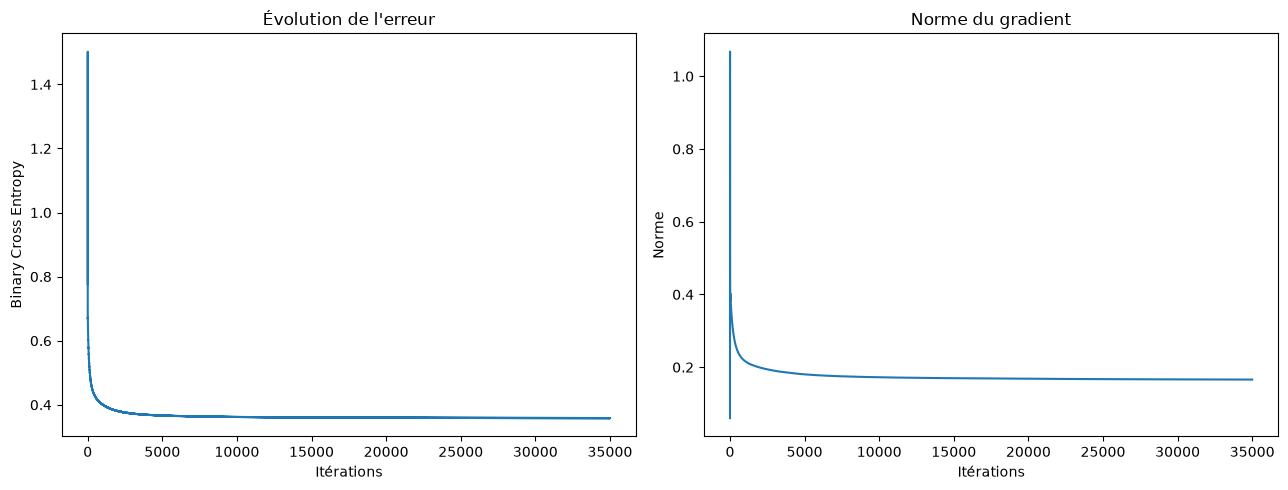


Erreur initiale : 0.777110770480575
Erreur finale : 0.3582772362441483
Norme finale du gradient : 0.16597114682943293


In [10]:
"""
Entrainement du modèle de régression logistique sur les données d'entraînement
"""
(RawData,RawC)=LireDonnees(FICHIER_ENTRAINEMENT)
(D,C)=CreerData(RawData,RawC)
(weights,constant, erreur)=Algorithme_Gradient()

In [11]:
def Prediction(weights: np.ndarray, constant: float, v: np.ndarray) -> int:
    """
        Prediction : Calcule la prédiction pour un vecteur donné en utilisant les poids et la constante appris.
        Entrées:
            -weights (np.ndarray): Les poids du modèle.
            -constant (float): La constante du modèle.
            -v (np.ndarray): Le vecteur à partir duquel on veut prédire.
        Sortie:
            -int: Le résultat de la prédiction (1 si la probabilité est supérieure à 0.5, sinon 0).
        Necessite: Les poids et le vecteur doivent être valides et de dimensions compatibles.
        Entraine : rien
        Variables globales : aucune
        Variables locales :
            -weights les poids du modèle
            -constant la constante du modèle
            -v le vecteur à partir duquel on veut prédire
        Utilise : 
            -la fonction Sigmoid() pour calculer la probabilité.
            -la fonction H() pour calculer l'activation du modèle.
    """
    if Sigmoid(H(weights, constant, v))>0.5:
            return 1
    else: 
            return 0

In [12]:
def PredictionsOnBase(weights: np.ndarray, constant: float, D: np.ndarray) -> list[int]:
    """
    PredictionsOnBase : Calcule les prédictions pour une base de données donnée en utilisant les poids et la constante appris.
    Entrées:
        -weights (np.ndarray): Les poids du modèle.
        -constant (float): La constante du modèle.
        -D (np.ndarray): La base de données de vecteurs à partir de laquelle on veut prédire.
    Sortie:
        -list[int]: Le vecteur des prédictions associées à chaque vecteur de la base de données.
    Necessite: Les poids et la base de données doivent être valides et de dimensions compatibles.
    Entraine : rien
    Variables globales : aucune
    Variables locales :
        -Cpred (list[int]): Le vecteur des prédictions associées à chaque vecteur de la base de données.
        -index (int): L'indice de la ligne en cours de traitement dans la base de données.
        -p (np.ndarray): La ligne de données en cours de traitement dans la base de données.
    Utilise : 
        -la fonction Prediction() pour calculer la prédiction pour chaque vecteur de la base de données.
    """
    Cpred: list[int] = []
    for index in range(len(D)):
        Cpred.append(Prediction(weights,constant,D[index:index+1,:]))
    return Cpred

In [14]:
# Pour exécuter ce code vous devez avoir au préalable exécuté l'apprentissage => on doit disposer des weights et constant

Cpred=PredictionsOnBase(weights,constant,CreerData(*LireDonnees(FICHIER_PREDICTION))[0])
GoodPred=0
VraiPositifs=0
FauxPositifs=0
VraiNegatifs=0
FauxNegatifs=0
NumberPositif=0
for index in range(len(CreerData(*LireDonnees(FICHIER_PREDICTION))[1])):
    if (C[index]==1):
        NumberPositif +=1
    if (C[index]==Cpred[index]):
        GoodPred+=1
    if (C[index]==1):
        if (Cpred[index]==1):
            VraiPositifs+=1
        else:
            FauxNegatifs+=1
    if (C[index]==0):
        if (Cpred[index]==1):
            FauxPositifs+=1
        else:
            VraiNegatifs+=1
print("Taux de bonnes classifications : ",100.0*GoodPred/len(C),"%")
print("Quand il fallait prédire 1...")
print(100.0*VraiPositifs/NumberPositif,"% du temps le prédicteur prédit 1")
print(100.0*FauxNegatifs/NumberPositif,"% du temps le prédicteur prédit 0")
print("Quand il fallait prédire 0...")
print(100.0*VraiNegatifs/(len(C)-NumberPositif),"% du temps le prédicteur prédit 0")
print(100.0*FauxPositifs/(len(C)-NumberPositif),"% du temps le prédicteur prédit 1")

Taux de bonnes classifications :  52.8 %
Quand il fallait prédire 1...
45.45454545454545 % du temps le prédicteur prédit 1
54.54545454545455 % du temps le prédicteur prédit 0
Quand il fallait prédire 0...
59.689922480620154 % du temps le prédicteur prédit 0
37.2093023255814 % du temps le prédicteur prédit 1
